# CloudLens: when does filling cloud-covered pixels help land-cover classification?
**AI61201 Visual Computing with AI/ML** · P. Sai Dharanidhar Ram (24AI10004), Ruthvik Devarakonda (24AI10023) · Mentor: Prof. Somdyuti Paul

Inference-only notebook. It **loads trained weights and stored experiment outputs** and reproduces the report/slide results:
Table I (accuracy), Table II (opacity sweep), Table III (RICE real clouds), Tables IV–VI (metric validity, harmful flips), failure taxonomy, Table VII (transfer learning), qualitative strips.

**Assets.** Everything is read from one folder containing `models/`, `results/` and `data/` (built with `make_assets_zip.py`).
Set one of `ASSETS_GDRIVE_ID`, `ASSETS_URL` or `PROJECT_DIR` in the config cell, or attach the folder as a Kaggle dataset / Drive folder.

In [1]:
import os, sys, glob, json, time, zipfile, warnings, subprocess, urllib.request
from pathlib import Path
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F, torchvision
from PIL import Image
from scipy.ndimage import gaussian_filter, distance_transform_edt
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
try:
    import cv2
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "opencv-python-headless"], check=False)
    import cv2
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 60)
dev = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", dev, "| torch", torch.__version__)

device: cuda | torch 2.14.1+cu126


## 0. Config and assets

In [2]:
# ------------------------------- CONFIG -------------------------------
ASSETS_GDRIVE_ID = ""      # Google Drive file id of cloudlens_assets.zip (made with make_assets_zip.py)
ASSETS_URL       = ""      # or a direct download link to the same zip
PROJECT_DIR      = ""      # or a folder that already contains models/ results/ data/
N_LIVE    = 4050 if dev == "cuda" else 1000   # test tiles for the live re-evaluation (4050 = full split)
N_BOOT    = 200            # bootstrap repetitions for Spearman CIs (report used 1000)
N_OPACITY = 500            # tiles for the opacity sweep (report: 500)
# ----------------------------------------------------------------------

def _is_base(d):
    d = Path(d)
    return (d / "models" / "resnet18_clean.pth").exists() and (d / "data" / "splits" / "test.csv").exists()

def find_base():
    cands = [PROJECT_DIR, "cloud_removal_project", ".", "..", "cloudlens_assets", "/content/cloudlens_assets",
             "/content/drive/MyDrive/cloud_removal_project", "/content/drive/MyDrive/cloudlens_assets"]
    cands += glob.glob("/kaggle/input/*") + glob.glob("/kaggle/input/*/*") + glob.glob("/content/*")
    for d in cands:
        if d and os.path.isdir(d) and _is_base(d):
            return Path(d).resolve()
    for root in ["/kaggle/input", "/content", "."]:
        for p in glob.glob(os.path.join(root, "**", "resnet18_clean.pth"), recursive=True):
            d = Path(p).parent.parent
            if _is_base(d):
                return d.resolve()
    return None

BASE = find_base()
if BASE is None and (ASSETS_GDRIVE_ID or ASSETS_URL):
    zpath = Path("cloudlens_assets.zip")
    if ASSETS_GDRIVE_ID:
        try:
            import gdown
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "-q", "install", "gdown"], check=False)
            import gdown
        gdown.download(id=ASSETS_GDRIVE_ID, output=str(zpath), quiet=False)
    else:
        urllib.request.urlretrieve(ASSETS_URL, str(zpath))
    with zipfile.ZipFile(zpath) as z:
        z.extractall("cloudlens_assets")
    BASE = find_base()
assert BASE is not None, ("Assets not found. Set ASSETS_GDRIVE_ID / ASSETS_URL / PROJECT_DIR in the config cell "
                          "(folder must contain models/, results/, data/splits/test.csv).")
RES = BASE / "results"
print("assets:", BASE)
print("models :", sorted(p.name for p in (BASE / "models").glob("*.pth")))

def find_file(name, avoid=None):
    hits = [p for p in RES.rglob(name) if not (avoid and avoid in str(p))]
    return hits[0] if hits else None

def read_csv(name, avoid=None):
    p = find_file(name, avoid)
    return pd.read_csv(p) if p is not None else None

SUMMARY = []   # (claim, paper value, value from this notebook)

assets: D:\cloud_removal_project\cloud_removal_project
models : ['resnet18_clean.pth', 'resnet18_fill_aware.pth', 'resnet18_mask_aware.pth', 'rice_big.pth', 'rice_big_gan.pth', 'rice_paired_big.pth', 'rice_paired_small.pth', 'rice_small.pth', 'unet_inpaint.pth', 'unet_transfer_sat_pretrain_seed0.pth', 'unet_transfer_unet_imagenet_lr0.0001_seed0.pth', 'unet_transfer_unet_imagenet_seed0.pth', 'unet_transfer_unet_rand_seed0.pth', 'unet_transfer_unet_sat_seed0.pth']


## 1. Code used by the experiments (cloud simulator, fills, networks)

In [3]:
BINS = {"10-30%": (0.10, 0.30), "30-60%": (0.30, 0.60), "60-80%": (0.60, 0.80)}
CLASSES = ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial',
           'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']

class CloudSimulator:
    def __init__(self, h=64, w=64):
        self.h, self.w = h, w
    def generate_cloud_mask(self, target_bin=(0.30, 0.60), rng=None):
        rng = rng if rng is not None else np.random.default_rng()
        low, high = target_bin
        cov = rng.uniform(low, high)
        n1 = rng.standard_normal((self.h, self.w)); n2 = rng.standard_normal((self.h, self.w)); n3 = rng.standard_normal((self.h, self.w))
        s1 = gaussian_filter(n1, sigma=rng.uniform(6.0, 12.0))
        s2 = gaussian_filter(n2, sigma=rng.uniform(3.0, 6.0))
        s3 = gaussian_filter(n3, sigma=rng.uniform(1.0, 2.5))
        comb = s1 * 0.6 + s2 * 0.3 + s3 * 0.1
        gx, gy = rng.uniform(-1, 1), rng.uniform(-1, 1)
        xx, yy = np.meshgrid(np.linspace(-1, 1, self.w), np.linspace(-1, 1, self.h))
        comb = comb + 0.3 * (gx * xx + gy * yy)
        thr = np.percentile(comb, 100.0 * (1.0 - cov))
        return (comb >= thr).astype(np.uint8)

def apply_thick(clean, mask, rng):
    clean_f = clean.astype(np.float32); H, W, _ = clean.shape
    base = np.clip(rng.normal(loc=238.0, scale=8.0, size=(H, W, 1)).astype(np.float32), 210.0, 255.0)
    base = np.repeat(base, 3, axis=-1)
    m3 = np.repeat(mask[:, :, np.newaxis], 3, axis=-1)
    return np.clip(clean_f * (1.0 - m3) + base * m3, 0, 255).astype(np.uint8)

def apply_opacity(clean, mask, alpha, rng):
    H, W, _ = clean.shape
    base = np.clip(rng.normal(238.0, 8.0, (H, W, 1)), 210, 255).astype(np.float32).repeat(3, -1)
    m = mask[..., None].astype(np.float32); c = clean.astype(np.float32)
    return np.clip(c * (1 - m) + (alpha * base + (1 - alpha) * c) * m, 0, 255).astype(np.uint8)

def masked_input(img, mask, v=0):
    o = img.copy(); o[mask == 1] = v; return o

def mean_fill(img, mask):
    o = img.copy(); un = mask == 0
    mu = [img[:, :, c][un].mean() for c in range(3)] if un.sum() > 0 else [128.0] * 3
    for c in range(3):
        o[mask == 1, c] = np.uint8(np.clip(mu[c], 0, 255))
    return o

def nearest_neighbor_fill(img, mask):
    if mask.sum() == 0: return img.copy()
    if (mask == 0).sum() == 0: return np.zeros_like(img)
    _, idx = distance_transform_edt(mask, return_indices=True)
    o = np.zeros_like(img)
    for c in range(3):
        o[:, :, c] = img[:, :, c][idx[0], idx[1]]
    return o

def telea_inpaint(img, mask, radius=3):
    bgr = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
    out = cv2.inpaint(bgr, (mask * 255).astype(np.uint8), inpaintRadius=radius, flags=cv2.INPAINT_TELEA)
    return cv2.cvtColor(out, cv2.COLOR_BGR2RGB)

def _dark(img, patch):
    return cv2.erode(img.min(axis=2), np.ones((patch, patch), np.uint8))

def dehaze_dcp(rgb, patch=7, omega=0.95, t0=0.1, top=0.01):
    I = rgb.astype(np.float32) / 255.0
    dark = _dark(I, patch)
    n = max(1, int(dark.size * top))
    idx = np.argsort(dark.ravel())[-n:]
    px = I.reshape(-1, 3)[idx]
    A = px[px.sum(1).argmax()].clip(0.3, 1.0)
    t = 1.0 - omega * _dark(I / A, patch)
    t = cv2.GaussianBlur(t, (0, 0), 2).clip(t0, 1.0)[..., None]
    J = (I - A) / t + A
    return (J.clip(0, 1) * 255).astype(np.uint8)

def dehaze_dcp_masked(rgb, mask, **kw):
    return np.where(mask[..., None].astype(bool), dehaze_dcp(rgb, **kw), rgb)

class DoubleConv(nn.Module):
    def __init__(self, i, o):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                                 nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True))
    def forward(self, x): return self.net(x)

class SmallUNetInpainter(nn.Module):
    def __init__(self, in_channels=4, out_channels=3, base_channels=32):
        super().__init__()
        b = base_channels
        self.inc = DoubleConv(in_channels, b)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(b, b * 2))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(b * 2, b * 4))
        self.bottleneck = nn.Sequential(nn.MaxPool2d(2), DoubleConv(b * 4, b * 8))
        self.up1 = nn.ConvTranspose2d(b * 8, b * 4, 2, 2); self.conv_up1 = DoubleConv(b * 8, b * 4)
        self.up2 = nn.ConvTranspose2d(b * 4, b * 2, 2, 2); self.conv_up2 = DoubleConv(b * 4, b * 2)
        self.up3 = nn.ConvTranspose2d(b * 2, b, 2, 2);     self.conv_up3 = DoubleConv(b * 2, b)
        self.outc = nn.Sequential(nn.Conv2d(b, out_channels, 1), nn.Sigmoid())
    def forward(self, x_masked, mask):
        x1 = self.inc(torch.cat([x_masked, mask], 1)); x2 = self.down1(x1); x3 = self.down2(x2)
        xb = self.bottleneck(x3)
        d1 = self.conv_up1(torch.cat([self.up1(xb), x3], 1))
        d2 = self.conv_up2(torch.cat([self.up2(d1), x2], 1))
        d3 = self.conv_up3(torch.cat([self.up3(d2), x1], 1))
        return x_masked * (1.0 - mask) + self.outc(d3) * mask

def _block(i, o):
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                         nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True))

def _up(x, ref):
    return F.interpolate(x, size=ref.shape[-2:], mode="bilinear", align_corners=False)

def _resnet_encoder(in_ch):
    m = torchvision.models.resnet18(weights=None)
    if in_ch != 3:
        m.conv1 = nn.Conv2d(in_ch, 64, kernel_size=7, stride=2, padding=3, bias=False)
    return m

class ResUNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc = _resnet_encoder(4)
        self.dec4 = _block(512 + 256, 256); self.dec3 = _block(256 + 128, 128)
        self.dec2 = _block(128 + 64, 64);   self.dec1 = _block(64 + 64, 64)
        self.dec0 = _block(64, 32)
        self.out = nn.Sequential(nn.Conv2d(32, 3, 1), nn.Sigmoid())
    def forward(self, x_masked, mask):
        e = self.enc
        x = torch.cat([x_masked, mask], 1)
        x0 = e.relu(e.bn1(e.conv1(x))); x1 = e.layer1(e.maxpool(x0))
        x2 = e.layer2(x1); x3 = e.layer3(x2); x4 = e.layer4(x3)
        d = self.dec4(torch.cat([_up(x4, x3), x3], 1)); d = self.dec3(torch.cat([_up(d, x2), x2], 1))
        d = self.dec2(torch.cat([_up(d, x1), x1], 1));  d = self.dec1(torch.cat([_up(d, x0), x0], 1))
        return self.out(self.dec0(_up(d, x_masked)))

def get_classifier():
    m = torchvision.models.resnet18(weights=None)
    m.fc = nn.Linear(m.fc.in_features, 10)
    return m

MEAN = torch.tensor([0.485, 0.456, 0.406], device=dev).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=dev).view(1, 3, 1, 1)

def load_sd(p):
    try:
        return torch.load(p, map_location=dev, weights_only=True)
    except TypeError:
        return torch.load(p, map_location=dev)

@torch.no_grad()
def predict(model, imgs, bs=256):
    model.eval(); out = []
    for i in range(0, len(imgs), bs):
        x = torch.from_numpy(imgs[i:i + bs]).to(dev).permute(0, 3, 1, 2).float() / 255.0
        out.append(model((x - MEAN) / STD).argmax(1).cpu().numpy())
    return np.concatenate(out)

@torch.no_grad()
def net_fill(model, cloudy, masks, bs=256):
    model.eval(); out = []
    for i in range(0, len(cloudy), bs):
        x = torch.from_numpy(cloudy[i:i + bs]).to(dev).permute(0, 3, 1, 2).float() / 255.0
        m = torch.from_numpy(masks[i:i + bs]).to(dev).unsqueeze(1).float()
        out.append((model(x, m).permute(0, 2, 3, 1).cpu().numpy() * 255.0).clip(0, 255).astype(np.uint8))
    return np.concatenate(out)

sim = CloudSimulator(64, 64)
print("code ready")

code ready


## 2. Load trained models and the EuroSAT test split (4,050 tiles)

In [4]:
def load_clf(name):
    m = get_classifier(); m.load_state_dict(load_sd(BASE / "models" / name)); return m.to(dev).eval()

clf = {"clean": load_clf("resnet18_clean.pth"),
       "mask_aware": load_clf("resnet18_mask_aware.pth"),
       "fill_aware": load_clf("resnet18_fill_aware.pth")}
unet = SmallUNetInpainter().to(dev); unet.load_state_dict(load_sd(BASE / "models" / "unet_inpaint.pth")); unet.eval()

test_df = pd.read_csv(BASE / "data" / "splits" / "test.csv")
index = {p.name: p for p in (BASE / "data").rglob("*.jpg")}
if any(f not in index for f in test_df["filename"]):
    try:
        from torchvision.datasets import EuroSAT
        EuroSAT(root="/tmp/eurosat_dl", download=True)
        index.update({p.name: p for p in Path("/tmp/eurosat_dl").rglob("*.jpg")})
    except Exception as e:
        print("EuroSAT download failed:", repr(e))
X = np.stack([np.array(Image.open(index[f]).convert("RGB")) for f in test_df["filename"]])
y = test_df["label"].astype(int).values
print("test tiles:", X.shape, "| classes:", len(set(y)))

test tiles: (4050, 64, 64, 3) | classes: 10


## 3. Table I and main result: accuracy by coverage (3 seeds, full 4,050-tile test split)
Read from the stored three-way experiment outputs (`threeway_seed0/1/2.csv`; mean ± SD over seeds).

seeds: [np.int64(0), np.int64(1), np.int64(2)] | n per cell: 4050


**Table I. Downstream accuracy (mean ± SD over seeds)**

,classifier,input,10-30%,30-60%,60-80%
0,Fill-aware,Mean fill,0.935 ± 0.009,0.885 ± 0.010,0.789 ± 0.008
1,Fill-aware,Nearest neighbour,0.943 ± 0.009,0.903 ± 0.011,0.799 ± 0.010
2,Fill-aware,Telea,0.950 ± 0.007,0.916 ± 0.008,0.830 ± 0.015
3,Fill-aware,Scratch U-Net,0.948 ± 0.006,0.914 ± 0.006,0.826 ± 0.007
4,Fill-aware,Cloudy as-is,0.682 ± 0.060,0.348 ± 0.103,0.151 ± 0.056
5,Mask-aware,Masked (black fill),0.898 ± 0.013,0.833 ± 0.016,0.698 ± 0.022
6,Clean,Cloudy as-is,0.730 ± 0.041,0.343 ± 0.032,0.137 ± 0.014
7,Clean,Nearest neighbour,0.946 ± 0.009,0.810 ± 0.021,0.441 ± 0.039
8,Clean,Telea,0.942 ± 0.007,0.715 ± 0.032,0.267 ± 0.003
9,Clean,Scratch U-Net,0.939 ± 0.007,0.689 ± 0.039,0.255 ± 0.019


**Decision rule: best fill (fill-aware) minus masked (mask-aware), accuracy points per seed**

bin,10-30%,30-60%,60-80%
seed,,,
0,5.7,9.3,14.6
1,4.5,7.3,11.7
2,5.4,8.3,14.1


Pre-registered rule met (fill-aware > mask-aware in every seed and bin): True
Telea (fill-aware) minus masked (mask-aware), points: {'10-30%': np.float64(5.2), '30-60%': np.float64(8.3), '60-80%': np.float64(13.2)}


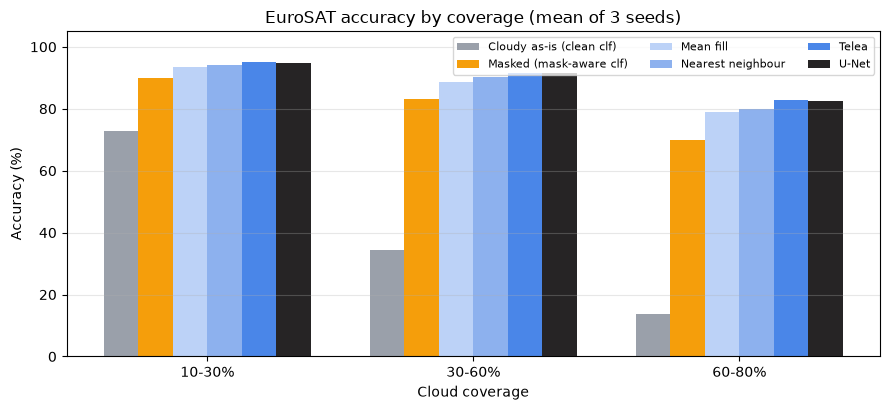

In [5]:
FILLS = ["mean_fill", "nearest_neighbor", "telea", "unet"]
PAPER = [("Fill-aware", "fill_aware", [("Mean fill", "mean_fill"), ("Nearest neighbour", "nearest_neighbor"), ("Telea", "telea"),
                                       ("Scratch U-Net", "unet"), ("Cloudy as-is", "cloudy")]),
         ("Mask-aware", "mask_aware", [("Masked (black fill)", "masked_zero")]),
         ("Clean", "clean", [("Cloudy as-is", "cloudy"), ("Nearest neighbour", "nearest_neighbor"), ("Telea", "telea"),
                             ("Scratch U-Net", "unet"), ("Mean fill", "mean_fill")])]

def table1(df, sd=True):
    rows = []
    for ctitle, c, items in PAPER:
        for label, inp in items:
            sub = df[(df.classifier == c) & (df.input == inp) & (df.bin != "all")]
            g = sub.groupby("bin").acc
            m, s = g.mean(), g.std(ddof=1)
            cells = []
            for b in BINS:
                if b not in m.index: cells.append("-")
                elif sd and not np.isnan(s[b]): cells.append(f"{m[b]:.3f} ± {s[b]:.3f}")
                else: cells.append(f"{m[b]:.3f}")
            rows.append([ctitle, label] + cells)
    return pd.DataFrame(rows, columns=["classifier", "input"] + list(BINS))

tw_files = sorted(RES.glob("threeway_seed*.csv"))
if tw_files:
    tw = pd.concat([pd.read_csv(f) for f in tw_files], ignore_index=True)
    print("seeds:", sorted(tw.seed.unique()), "| n per cell:", int(tw.n.iloc[0]))
    display(Markdown("**Table I. Downstream accuracy (mean ± SD over seeds)**"))
    display(table1(tw))

    gaps = []
    for seed, g in tw.groupby("seed"):
        for b in BINS:
            best = g[(g.classifier == "fill_aware") & g.input.isin(FILLS) & (g.bin == b)].acc.max()
            mk = g[(g.classifier == "mask_aware") & (g.input == "masked_zero") & (g.bin == b)].acc.iloc[0]
            gaps.append(dict(seed=seed, bin=b, best_fill_minus_masked_pts=round(100 * (best - mk), 1)))
    gp = pd.DataFrame(gaps).pivot(index="seed", columns="bin", values="best_fill_minus_masked_pts")
    display(Markdown("**Decision rule: best fill (fill-aware) minus masked (mask-aware), accuracy points per seed**"))
    display(gp)
    print("Pre-registered rule met (fill-aware > mask-aware in every seed and bin):", bool((gp.values > 0).all()))

    mean_tab = tw.groupby(["classifier", "input", "bin"]).acc.mean()
    tel_gap = {b: 100 * (mean_tab[("fill_aware", "telea", b)] - mean_tab[("mask_aware", "masked_zero", b)]) for b in BINS}
    print("Telea (fill-aware) minus masked (mask-aware), points:", {b: round(v, 1) for b, v in tel_gap.items()})
    SUMMARY += [("Fill-aware Telea minus masked, 10-30%", "+5.2", f"{tel_gap['10-30%']:+.1f}"),
                ("Fill-aware Telea minus masked, 30-60%", "+8.3", f"{tel_gap['30-60%']:+.1f}"),
                ("Fill-aware Telea minus masked, 60-80%", "+13.2", f"{tel_gap['60-80%']:+.1f}"),
                ("Telea vs U-Net at 60-80% (fill-aware)", "0.830 vs 0.826",
                 f"{mean_tab[('fill_aware','telea','60-80%')]:.3f} vs {mean_tab[('fill_aware','unet','60-80%')]:.3f}")]

    series = [("Cloudy as-is (clean clf)", "clean", "cloudy", "#9aa0aa"), ("Masked (mask-aware clf)", "mask_aware", "masked_zero", "#f59e0b"),
              ("Mean fill", "fill_aware", "mean_fill", "#bcd2f7"), ("Nearest neighbour", "fill_aware", "nearest_neighbor", "#8db1ee"),
              ("Telea", "fill_aware", "telea", "#4a86e8"), ("U-Net", "fill_aware", "unet", "#262425")]
    fig, ax = plt.subplots(figsize=(9, 4.2)); w = 0.13
    for i, (lab, c, inp, col) in enumerate(series):
        vals = [100 * mean_tab[(c, inp, b)] for b in BINS]
        ax.bar(np.arange(3) + (i - 2.5) * w, vals, w, label=lab, color=col)
    ax.set_xticks(range(3)); ax.set_xticklabels(list(BINS)); ax.set_ylabel("Accuracy (%)"); ax.set_ylim(0, 105)
    ax.set_xlabel("Cloud coverage"); ax.grid(axis="y", alpha=.3); ax.legend(fontsize=8, ncol=3, loc="upper right")
    ax.set_title("EuroSAT accuracy by coverage (mean of 3 seeds)"); plt.tight_layout(); plt.show()
else:
    print("threeway_seed*.csv not found: skipping")

## 4. Live re-evaluation with the saved checkpoints (inference only)
Re-runs cloud simulation, the four fills and the three classifiers on the test tiles. The saved checkpoints come from the first training run (one seed), so numbers differ by a few points from the 3-seed means above; the ranking and the decision rule are what to compare.

In [6]:
idxs = np.arange(len(X)) if N_LIVE >= len(X) else np.sort(np.random.default_rng(0).permutation(len(X))[:N_LIVE])
Xs, ys = X[idxs], y[idxs]

def make_cloudy(bi, brange, ids=idxs):
    ms, cs = [], []
    for idx in ids:
        rng = np.random.default_rng(42 + int(idx) * 10 + bi)   # same cloud seeds as the experiments
        m = sim.generate_cloud_mask(brange, rng=rng)
        ms.append(m); cs.append(apply_thick(X[idx], m, rng))
    return np.stack(cs), np.stack(ms)

def make_inputs(cl, mk):
    return {"cloudy": cl,
            "masked_zero": np.stack([masked_input(c, m, 0) for c, m in zip(cl, mk)]),
            "mean_fill": np.stack([mean_fill(c, m) for c, m in zip(cl, mk)]),
            "nearest_neighbor": np.stack([nearest_neighbor_fill(c, m) for c, m in zip(cl, mk)]),
            "telea": np.stack([telea_inpaint(c, m) for c, m in zip(cl, mk)]),
            "unet": net_fill(unet, cl, mk)}

t0 = time.time(); live, harm = [], []
cp = {k: predict(m, Xs) for k, m in clf.items()}
for k in clf:
    live.append(dict(classifier=k, bin="all", input="clean", acc=float((cp[k] == ys).mean())))
for bi, (bn, br) in enumerate(BINS.items()):
    cl, mk = make_cloudy(bi, br)
    for inp, arr in make_inputs(cl, mk).items():
        for k, m_ in clf.items():
            p = predict(m_, arr)
            live.append(dict(classifier=k, bin=bn, input=inp, acc=float((p == ys).mean())))
            if k == "fill_aware" and inp in FILLS:
                harm.append(dict(method=inp, bin=bn, harmful_pct=100 * float(((cp[k] == ys) & (p != ys)).mean())))
live = pd.DataFrame(live); harm = pd.DataFrame(harm)
print(f"{len(idxs)} tiles, {time.time() - t0:.0f}s")
print("clean-tile accuracy:", live[live.input == "clean"].set_index("classifier").acc.round(4).to_dict())
display(Markdown("**Table I (live, saved checkpoints)**")); display(table1(live, sd=False))
lg = {}
for b in BINS:
    best = live[(live.classifier == "fill_aware") & live.input.isin(FILLS) & (live.bin == b)].acc.max()
    mk_ = live[(live.classifier == "mask_aware") & (live.input == "masked_zero") & (live.bin == b)].acc.iloc[0]
    lg[b] = round(100 * (best - mk_), 1)
print("best fill (fill-aware) minus masked (mask-aware), points:", lg, "| rule holds:", all(v > 0 for v in lg.values()))
display(Markdown("**Harmful-flip rate (%), fill-aware classifier (live)**"))
display(harm.pivot(index="method", columns="bin", values="harmful_pct").round(1).reindex(["telea", "unet", "nearest_neighbor", "mean_fill"]))

4050 tiles, 59s
clean-tile accuracy: {'clean': 0.9506, 'mask_aware': 0.9612, 'fill_aware': 0.9632}


**Table I (live, saved checkpoints)**

,classifier,input,10-30%,30-60%,60-80%
0,Fill-aware,Mean fill,0.945,0.899,0.807
1,Fill-aware,Nearest neighbour,0.958,0.915,0.836
2,Fill-aware,Telea,0.959,0.927,0.856
3,Fill-aware,Scratch U-Net,0.956,0.923,0.851
4,Fill-aware,Cloudy as-is,0.602,0.346,0.163
5,Mask-aware,Masked (black fill),0.906,0.831,0.697
6,Clean,Cloudy as-is,0.707,0.414,0.161
7,Clean,Nearest neighbour,0.927,0.755,0.398
8,Clean,Telea,0.915,0.574,0.235
9,Clean,Scratch U-Net,0.908,0.556,0.223


best fill (fill-aware) minus masked (mask-aware), points: {'10-30%': np.float64(5.4), '30-60%': np.float64(9.6), '60-80%': np.float64(15.9)} | rule holds: True


**Harmful-flip rate (%), fill-aware classifier (live)**

bin,10-30%,30-60%,60-80%
method,,,
telea,1.3,4.6,12.1
unet,1.7,5.0,12.7
nearest_neighbor,1.6,6.1,14.1
mean_fill,2.9,7.6,17.1


## 5. Metric validity and harmful flips (Tables IV, V, VI)
From the tile-level results (`metric_validity_tiles_seed0.csv`: 4,050 tiles × 3 bins × 4 fills). Spearman ρ between each metric and the harmful-flip indicator, tile-level bootstrap CIs (`N_BOOT` repetitions; the report used 1000).

**Table IV. Spearman ρ with harmful flips (pooled, n = 4050 tiles, 200 bootstrap reps)**

,metric,expected sign,pooled ρ,95% CI
0,Whole-tile SSIM,negative,-0.21,"[-0.22, -0.20]"
1,Full-tile LPIPS,positive,+0.22,"[+0.21, +0.23]"
2,In-mask PSNR,negative,-0.12,"[-0.14, -0.11]"
3,In-mask SSIM,negative,-0.09,"[-0.11, -0.08]"


**Table V. Within-method Spearman ρ with harmful flips**

,fill,SSIM (full),LPIPS,PSNR (mask),SSIM (mask)
0,mean_fill,-0.21,+0.22,-0.13,-0.06
1,nearest_neighbor,-0.23,+0.24,-0.13,-0.13
2,telea,-0.20,+0.21,-0.11,-0.09
3,unet,-0.19,+0.20,-0.11,-0.09


whole-tile SSIM ρ within each bin: {'10-30%': np.float64(-0.08), '30-60%': np.float64(-0.11), '60-80%': np.float64(-0.12)}


**Table VI. Harmful-flip rate (%) by fill and coverage**

bin,10-30%,30-60%,60-80%
method,,,
telea,1.5,4.9,13.9
unet,1.7,5.4,14.1
nearest_neighbor,2.1,6.0,15.9
mean_fill,3.2,7.5,17.9


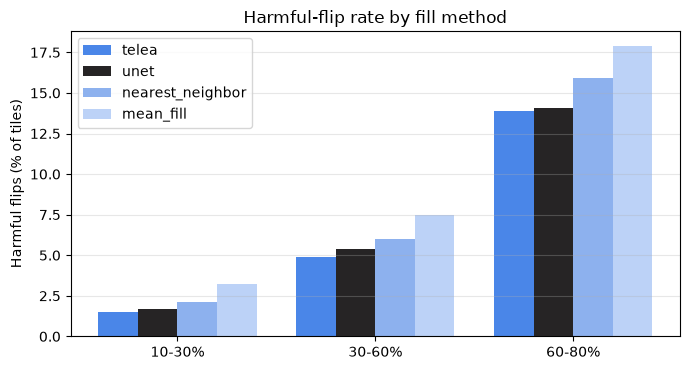

In [7]:
mv = read_csv("metric_validity_tiles_seed0.csv")
if mv is not None:
    mv["tile"] = mv.groupby(["bin", "method"]).cumcount()
    mv["cond"] = mv["bin"] + "|" + mv["method"]
    conds = sorted(mv.cond.unique())
    cb = np.array([c.split("|")[0] for c in conds]); cm = np.array([c.split("|")[1] for c in conds])
    mat = lambda col: mv.pivot(index="tile", columns="cond", values=col)[conds].values
    H = mat("harmful").astype(float)
    NAMES = {"ssim_full": "Whole-tile SSIM", "lpips": "Full-tile LPIPS", "psnr_mask": "In-mask PSNR", "ssim_mask": "In-mask SSIM"}
    M = {k: mat(k) for k in NAMES}

    def rho(a, b):
        a, b = np.ravel(a), np.ravel(b); ok = np.isfinite(a) & np.isfinite(b)
        return spearmanr(a[ok], b[ok])[0]

    def boot(cols, k):
        r0 = rho(M[k][:, cols], H[:, cols]); rng = np.random.default_rng(0); n = H.shape[0]; bs = []
        for _ in range(N_BOOT):
            i = rng.integers(0, n, n); bs.append(rho(M[k][i][:, cols], H[i][:, cols]))
        lo, hi = np.nanpercentile(bs, [2.5, 97.5]); return r0, lo, hi

    allc = np.arange(len(conds)); rows4 = []
    for k, nm in NAMES.items():
        r0, lo, hi = boot(allc, k)
        rows4.append([nm, "positive" if k == "lpips" else "negative", f"{r0:+.2f}", f"[{lo:+.2f}, {hi:+.2f}]"])
        SUMMARY.append((f"Pooled rho vs harmful flips: {nm}", {"ssim_full": "-0.21", "lpips": "+0.22", "psnr_mask": "-0.12", "ssim_mask": "-0.09"}[k], f"{r0:+.2f}"))
    display(Markdown(f"**Table IV. Spearman ρ with harmful flips (pooled, n = {H.shape[0]} tiles, {N_BOOT} bootstrap reps)**"))
    display(pd.DataFrame(rows4, columns=["metric", "expected sign", "pooled ρ", "95% CI"]))

    rows5 = []
    for m_ in ["mean_fill", "nearest_neighbor", "telea", "unet"]:
        cols = np.where(cm == m_)[0]
        rows5.append([m_] + [f"{rho(M[k][:, cols], H[:, cols]):+.2f}" for k in ["ssim_full", "lpips", "psnr_mask", "ssim_mask"]])
    display(Markdown("**Table V. Within-method Spearman ρ with harmful flips**"))
    display(pd.DataFrame(rows5, columns=["fill", "SSIM (full)", "LPIPS", "PSNR (mask)", "SSIM (mask)"]))
    print("whole-tile SSIM ρ within each bin:", {b: round(rho(M["ssim_full"][:, cb == b], H[:, cb == b]), 2) for b in BINS})

    t6 = (mv.groupby(["method", "bin"]).harmful.mean().mul(100).round(1).unstack()
          .reindex(["telea", "unet", "nearest_neighbor", "mean_fill"])[list(BINS)])
    display(Markdown("**Table VI. Harmful-flip rate (%) by fill and coverage**")); display(t6)
    SUMMARY.append(("Harmful flips, Telea 60-80% / mean fill 60-80%", "13.9 / 17.9", f"{t6.loc['telea','60-80%']} / {t6.loc['mean_fill','60-80%']}"))

    fig, ax = plt.subplots(figsize=(7, 3.8)); cols_ = {"telea": "#4a86e8", "unet": "#262425", "nearest_neighbor": "#8db1ee", "mean_fill": "#bcd2f7"}
    for i, m_ in enumerate(t6.index):
        ax.bar(np.arange(3) + (i - 1.5) * 0.2, t6.loc[m_].values, 0.2, label=m_, color=cols_[m_])
    ax.set_xticks(range(3)); ax.set_xticklabels(list(BINS)); ax.set_ylabel("Harmful flips (% of tiles)"); ax.legend(); ax.grid(axis="y", alpha=.3)
    ax.set_title("Harmful-flip rate by fill method"); plt.tight_layout(); plt.show()
else:
    print("metric_validity_tiles_seed0.csv not found: skipping")
    for nm in ["metric_validity_tile_summary_seed0.csv", "within_method_summary_seed0.csv"]:
        d = read_csv(nm)
        if d is not None: display(d)

## 6. Opacity sweep and dehazing (Table II)
Live: 30–60% coverage, clean classifier, semi-transparent clouds of opacity α. Telea and mean fill overwrite the masked pixels, so they do not depend on α; dehazing (dark channel prior) uses the raw pixels.

**Table II. Accuracy vs opacity (n = 500 tiles, clean classifier)**

method,cloudy_as_is,mean_fill,telea_inpaint,dark_channel,dark_channel_masked
alpha,,,,,
0.20,0.826,0.478,0.584,0.584,0.758
0.35,0.712,0.478,0.586,0.496,0.664
0.50,0.650,0.478,0.584,0.406,0.558
0.65,0.592,0.478,0.584,0.346,0.480
0.80,0.520,0.478,0.584,0.302,0.390
0.95,0.452,0.478,0.584,0.246,0.310
1.00,0.408,0.478,0.584,0.226,0.294


approx. 95% half-width: ±0.043
crossover opacity (cloudy-as-is drops below Telea): 0.67


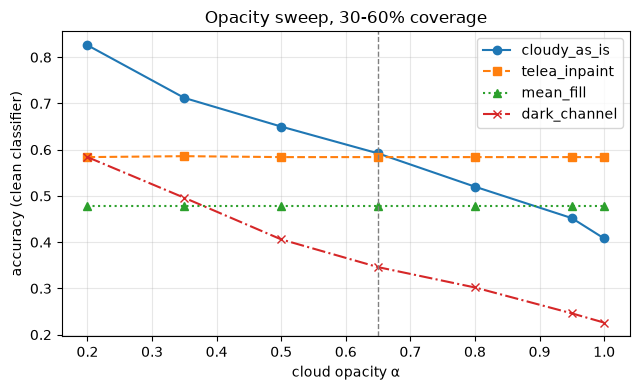

**LPIPS vs opacity (stored output)**

method,cloudy_as_is,dark_channel,dark_channel_masked,mean_fill,telea_inpaint
alpha,,,,,
0.20,0.132,0.228,0.163,0.19,0.179
0.35,0.234,0.305,0.230,0.19,0.179
0.50,0.322,0.377,0.310,0.19,0.179
0.65,0.395,0.446,0.395,0.19,0.179
0.80,0.454,0.518,0.493,0.19,0.179
0.95,0.495,0.588,0.590,0.19,0.179
1.00,0.505,0.601,0.606,0.19,0.179


In [8]:
ALPHAS = [0.2, 0.35, 0.5, 0.65, 0.8, 0.95, 1.0]
OPM = {"cloudy_as_is": lambda c, m: c, "mean_fill": mean_fill, "telea_inpaint": telea_inpaint,
       "dark_channel": lambda c, m: dehaze_dcp(c), "dark_channel_masked": dehaze_dcp_masked}
sel = test_df.sample(n=min(N_OPACITY, len(test_df)), random_state=0).index.values
Xo, yo = X[sel], y[sel]
rows = []
for a in ALPHAS:
    outs = {k: [] for k in OPM}
    for idx, img in enumerate(Xo):
        rng = np.random.default_rng(42 + idx)
        mask = sim.generate_cloud_mask((0.30, 0.60), rng=rng)
        cloudy = apply_opacity(img, mask, a, rng)
        for k, f in OPM.items():
            outs[k].append(f(cloudy, mask))
    for k in OPM:
        acc = float((predict(clf["clean"], np.stack(outs[k])) == yo).mean())
        rows.append(dict(alpha=a, method=k, acc=acc, ci95=1.96 * np.sqrt(acc * (1 - acc) / len(yo))))
op = pd.DataFrame(rows)
tab2 = op.pivot(index="alpha", columns="method", values="acc")[list(OPM)]
display(Markdown(f"**Table II. Accuracy vs opacity (n = {len(yo)} tiles, clean classifier)**")); display(tab2.round(3))
ci_ = op[op.method == "telea_inpaint"].ci95.mean(); print(f"approx. 95% half-width: ±{ci_:.3f}")

cl_, te_ = tab2["cloudy_as_is"].values, tab2["telea_inpaint"].values[0]
cross = None
for i in range(len(ALPHAS) - 1):
    if cl_[i] >= te_ > cl_[i + 1]:
        cross = ALPHAS[i] + (ALPHAS[i + 1] - ALPHAS[i]) * (cl_[i] - te_) / (cl_[i] - cl_[i + 1]); break
print("crossover opacity (cloudy-as-is drops below Telea):", None if cross is None else round(cross, 2))
SUMMARY += [("Opacity crossover alpha", "~0.65 (sampled points; interpolated value shown)", "n/a" if cross is None else f"{cross:.2f}"),
            ("DCP (masked) at alpha 0.2 vs cloudy", "0.758 vs 0.826", f"{tab2.loc[0.2,'dark_channel_masked']:.3f} vs {tab2.loc[0.2,'cloudy_as_is']:.3f}"),
            ("DCP at alpha 1.0", "0.226", f"{tab2.loc[1.0,'dark_channel']:.3f}")]
fig, ax = plt.subplots(figsize=(6.5, 4))
for k, st in [("cloudy_as_is", "o-"), ("telea_inpaint", "s--"), ("mean_fill", "^:"), ("dark_channel", "x-.")]:
    ax.plot(ALPHAS, tab2[k].values, st, label=k)
ax.axvline(0.65, color="gray", ls="--", lw=1); ax.set_xlabel("cloud opacity α"); ax.set_ylabel("accuracy (clean classifier)")
ax.grid(alpha=.3); ax.legend(); ax.set_title("Opacity sweep, 30-60% coverage"); plt.tight_layout(); plt.show()
lp = read_csv("opacity_sweep_v2.csv")
if lp is not None and "metric" in lp.columns:
    display(Markdown("**LPIPS vs opacity (stored output)**"))
    display(lp[lp.metric == "lpips"].pivot(index="alpha", columns="method", values="mean").round(3))

## 7. Failure taxonomy (manual audit of 60 harmful flips, 15 per fill) and water-body collapse

**Manual labels (counts)**

manual_label,color_shift,lost_structure,other,texture_hallucination
method,,,,
mean_fill,13,0,1,1
nearest_neighbor,0,4,1,10
telea_inpaint,2,8,3,2
unet,0,9,2,4


**Manual labels (% of each method's audited flips)**

manual_label,color_shift,lost_structure,other,texture_hallucination
method,,,,
mean_fill,86.7,0.0,6.7,6.7
nearest_neighbor,0.0,26.7,6.7,66.7
telea_inpaint,13.3,53.3,20.0,13.3
unet,0.0,60.0,13.3,26.7


**Where harmful flips go (clean classifier, fills only)**

,method,coverage_bin,n_rows,harmful_flips,harmful_rate_%,share_into_SeaLake_or_River_%,top_wrong_class
0,mean_fill,10-30%,200,21,10.5,19.0,Pasture
1,mean_fill,30-60%,200,90,45.0,92.2,SeaLake
2,mean_fill,60-80%,200,169,84.5,100.0,SeaLake
3,nearest_neighbor,10-30%,200,8,4.0,0.0,PermanentCrop
4,nearest_neighbor,30-60%,200,33,16.5,18.2,AnnualCrop
5,nearest_neighbor,60-80%,200,114,57.0,56.1,River
6,telea_inpaint,10-30%,200,13,6.5,7.7,AnnualCrop
7,telea_inpaint,30-60%,200,82,41.0,73.2,SeaLake
8,telea_inpaint,60-80%,200,149,74.5,85.2,SeaLake
9,unet,10-30%,200,12,6.0,8.3,AnnualCrop


share of harmful flips predicted SeaLake/River (%): {'mean_fill': 91.4, 'nearest_neighbor': 45.1, 'telea_inpaint': 77.0, 'unet': 85.1}


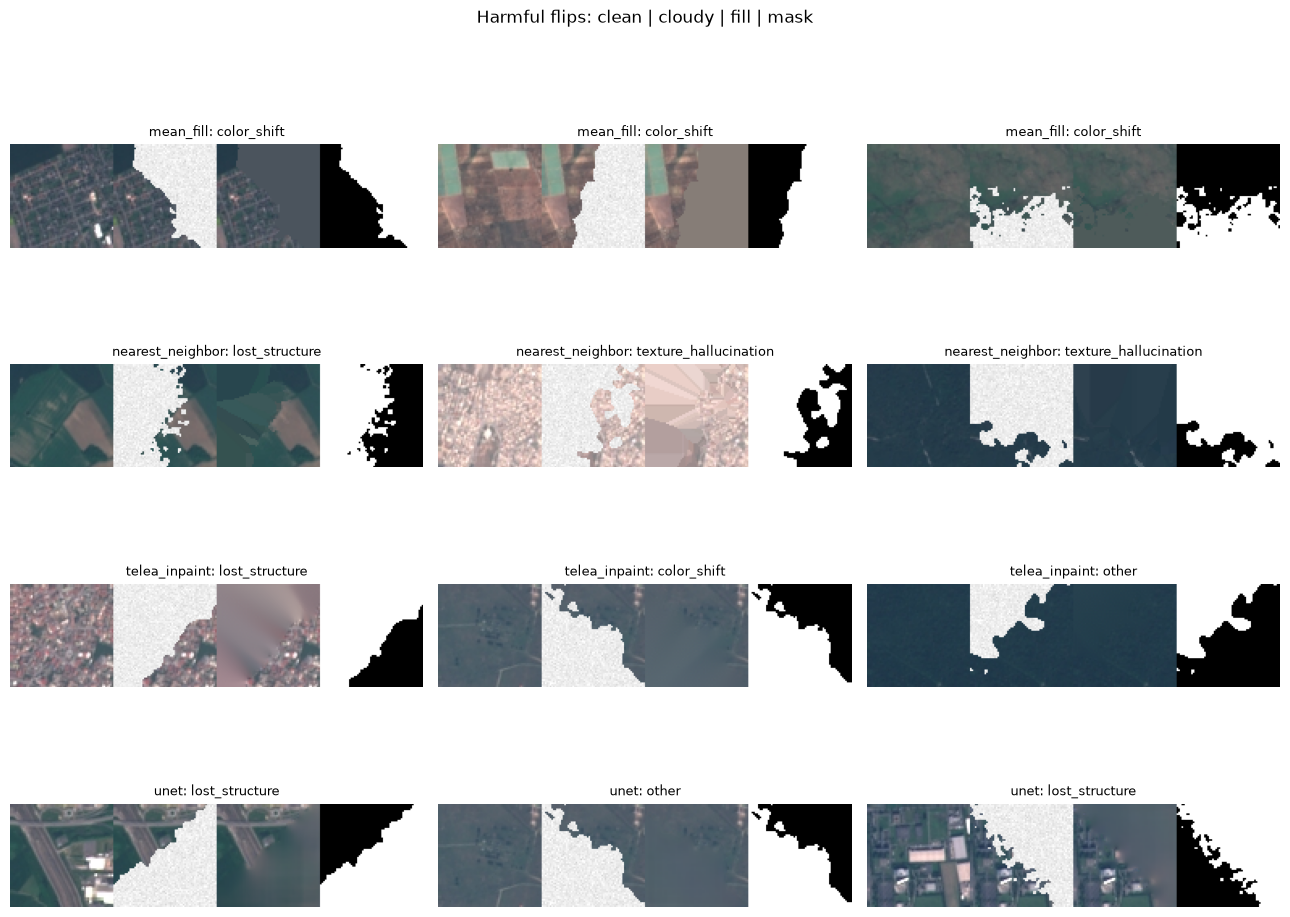

In [9]:
sheet = read_csv("manual_label_sheet.csv")
if sheet is not None:
    sheet = sheet[sheet.manual_label.notna() & (sheet.manual_label.astype(str).str.len() > 0)]
    ct = pd.crosstab(sheet.method, sheet.manual_label)
    display(Markdown("**Manual labels (counts)**")); display(ct)
    display(Markdown("**Manual labels (% of each method's audited flips)**")); display((ct.div(ct.sum(1), axis=0) * 100).round(1))
    for m_, lab, paper in [("nearest_neighbor", "texture_hallucination", "66.7%"), ("telea_inpaint", "lost_structure", "53.3%"), ("unet", "lost_structure", "60.0%")]:
        if m_ in ct.index and lab in ct.columns:
            SUMMARY.append((f"Taxonomy: {m_} -> {lab}", paper, f"{100 * ct.loc[m_, lab] / ct.loc[m_].sum():.1f}%"))
shift = read_csv("prediction_shift_fills.csv")
if shift is not None:
    display(Markdown("**Where harmful flips go (clean classifier, fills only)**")); display(shift)
    share = {}
    for m_, g in shift.groupby("method"):
        share[m_] = round(float((g["share_into_SeaLake_or_River_%"] * g["harmful_flips"]).sum() / max(g["harmful_flips"].sum(), 1)), 1)
    print("share of harmful flips predicted SeaLake/River (%):", share)
if sheet is not None:
    fig, axes = plt.subplots(4, 3, figsize=(13, 10))
    for r, m_ in enumerate(["mean_fill", "nearest_neighbor", "telea_inpaint", "unet"]):
        s = sheet[sheet.method == m_].head(3)
        for c in range(3):
            ax = axes[r, c]; ax.axis("off")
            if c < len(s):
                p = BASE / str(s.iloc[c]["audit_image"])
                if p.exists():
                    ax.imshow(plt.imread(p)); ax.set_title(f"{m_}: {s.iloc[c]['manual_label']}", fontsize=9)
    fig.suptitle("Harmful flips: clean | cloudy | fill | mask", y=1.0); plt.tight_layout(); plt.show()

## 8. Real clouds on RICE (Table III)
RICE has no land-cover labels, so classifier agreement with the clear-tile prediction is a proxy. Read from the stored RICE evaluation outputs (held-out tiles).

In [10]:
fid = read_csv("fidelity_summary_ci.csv", avoid="dil"); agr = read_csv("agreement_fill_aware.csv", avoid="dil")
if fid is not None:
    NM = {"cloudy_as_is": "Cloudy as-is", "paired_big": "Paired restorer (big)", "paired_small": "Paired restorer (small)",
          "dark_channel": "Dark channel prior", "mean_fill": "Mean fill", "euro_unet": "EuroSAT U-Net", "rice_small": "RICE U-Net (small)",
          "rice_big": "RICE U-Net (big)", "rice_big_gan": "RICE U-Net (big, GAN)", "nearest_neighbor": "Nearest neighbour", "telea_inpaint": "Telea"}
    tab = fid.copy()
    if agr is not None:
        tab = tab.merge(agr[["dataset", "method", "agreement_pct"]], on=["dataset", "method"], how="left")
    first = lambda s: float(str(s).split()[0])
    for d in ["RICE1", "RICE2"]:
        t = tab[tab.dataset == d].copy()
        t["order"] = t["lpips"].map(first); t = t.sort_values("order")
        t["method"] = t["method"].map(lambda m: NM.get(m, m))
        display(Markdown(f"**{d}**"))
        display(t[[c for c in ["method", "n_tiles", "lpips", "psnr_mask", "ssim_mask", "agreement_pct"] if c in t.columns]].reset_index(drop=True))
    try:
        r1 = tab[tab.dataset == "RICE1"].set_index("method")
        SUMMARY += [("RICE1 LPIPS, cloudy as-is", "0.149", f"{first(r1.loc['cloudy_as_is','lpips']):.3f}"),
                    ("RICE1 PSNR(mask), DCP vs cloudy", "not in report", f"{first(r1.loc['dark_channel','psnr_mask']):.1f} vs {first(r1.loc['cloudy_as_is','psnr_mask']):.1f}")]
        r2 = tab[tab.dataset == "RICE2"].set_index("method")
        SUMMARY += [("RICE2 agreement, paired big / cloudy", "84.3 / 46.2", f"{first(r2.loc['paired_big','agreement_pct']):.1f} / {first(r2.loc['cloudy_as_is','agreement_pct']):.1f}")]
    except Exception as e:
        print("summary rows skipped:", repr(e))
else:
    print("RICE evaluation outputs not found: skipping")

**RICE1**

,method,n_tiles,lpips,psnr_mask,ssim_mask,agreement_pct
0,Cloudy as-is,626,"0.149 [0.135, 0.165]","16.834 [16.545, 17.093]","0.770 [0.752, 0.788]","58.9 [46.9, 68.5]"
1,Paired restorer (big),626,"0.174 [0.149, 0.205]","32.124 [31.501, 32.666]","0.842 [0.823, 0.859]","71.3 [60.6, 79.8]"
2,Paired restorer (small),626,"0.178 [0.154, 0.211]","31.920 [31.190, 32.521]","0.837 [0.816, 0.855]","69.6 [60.0, 77.8]"
3,Dark channel prior,626,"0.189 [0.158, 0.231]","18.629 [17.471, 19.754]","0.793 [0.758, 0.822]","69.6 [62.6, 76.0]"
4,Nearest neighbour,626,"0.278 [0.256, 0.304]","14.721 [14.250, 15.141]","0.459 [0.420, 0.499]","47.7 [37.0, 57.3]"
5,EuroSAT U-Net,626,"0.298 [0.275, 0.324]","14.971 [14.395, 15.566]","0.456 [0.417, 0.495]","46.3 [35.6, 55.2]"
6,"RICE U-Net (big, GAN)",626,"0.298 [0.274, 0.324]","14.704 [14.161, 15.145]","0.442 [0.404, 0.482]","47.0 [34.1, 57.4]"
7,RICE U-Net (big),626,"0.309 [0.286, 0.335]","14.597 [14.098, 15.037]","0.449 [0.408, 0.491]","50.0 [38.6, 59.3]"
8,RICE U-Net (small),626,"0.318 [0.295, 0.343]","14.532 [14.006, 14.966]","0.438 [0.399, 0.478]","46.7 [35.6, 55.6]"
9,Telea,626,"0.329 [0.303, 0.358]","14.218 [13.697, 14.669]","0.417 [0.374, 0.462]","50.5 [39.7, 60.7]"


**RICE2**

,method,n_tiles,lpips,psnr_mask,ssim_mask,agreement_pct
0,"RICE U-Net (big, GAN)",717,"0.317 [0.293, 0.338]","22.921 [21.958, 23.919]","0.621 [0.581, 0.662]","59.4 [49.6, 70.4]"
1,RICE U-Net (small),717,"0.318 [0.295, 0.338]","23.002 [22.082, 23.993]","0.628 [0.589, 0.665]","65.5 [55.3, 75.1]"
2,Mean fill,717,"0.323 [0.299, 0.344]","26.423 [25.267, 27.676]","0.632 [0.594, 0.669]","81.5 [73.3, 88.9]"
3,Telea,717,"0.324 [0.298, 0.346]","22.373 [21.504, 23.211]","0.627 [0.590, 0.667]","65.1 [54.6, 74.8]"
4,RICE U-Net (big),717,"0.327 [0.302, 0.349]","22.260 [21.373, 23.219]","0.619 [0.581, 0.657]","64.7 [54.2, 73.9]"
5,Paired restorer (big),717,"0.336 [0.309, 0.358]","29.962 [29.074, 30.841]","0.580 [0.543, 0.620]","84.3 [76.2, 90.7]"
6,Nearest neighbour,717,"0.341 [0.313, 0.367]","21.346 [20.487, 22.247]","0.542 [0.502, 0.586]","56.6 [46.8, 67.2]"
7,Paired restorer (small),717,"0.342 [0.315, 0.365]","30.403 [29.388, 31.388]","0.576 [0.538, 0.618]","82.3 [75.3, 88.6]"
8,EuroSAT U-Net,717,"0.374 [0.355, 0.391]","20.848 [20.124, 21.582]","0.571 [0.538, 0.604]","58.6 [50.2, 67.7]"
9,Cloudy as-is,717,"0.402 [0.364, 0.436]","16.216 [14.927, 17.873]","0.375 [0.315, 0.444]","46.2 [36.2, 58.4]"


## 9. Transfer learning (Table VII)
Stored scores (fill-aware classifier retrained in that run), plus an optional live check that loads the saved ResNet-18-encoder U-Nets.

In [11]:
tr_files = sorted(RES.glob("unet_transfer_seed0*.csv"))
if tr_files:
    best = max(tr_files, key=lambda p: len(pd.read_csv(p).method.unique()))
    tr = pd.read_csv(best)
    LAB = {"unet_scratch_ref": "Scratch U-Net (ref.)", "unet_imagenet": "ResNet-18 (ImageNet, 1e-3)", "unet_sat": "ResNet-18 (Satellite, 1e-3)",
           "unet_imagenet_lr0.0001": "ResNet-18 (ImageNet, 1e-4)", "unet_rand": "ResNet-18 (Random, 1e-3)",
           "telea_ref": "Telea (ref.)", "nearest_neighbor_ref": "Nearest neighbour (ref.)"}
    t7 = tr.pivot(index="method", columns="bin", values="acc")[list(BINS)]
    t7.index = [LAB.get(m, m) for m in t7.index]
    display(Markdown(f"**Table VII (stored, {best.name})**")); display(t7.sort_values("60-80%", ascending=False).round(3))
    try:
        sc, im, rd = t7.loc["Scratch U-Net (ref.)"], t7.loc["ResNet-18 (ImageNet, 1e-3)"], t7.loc["ResNet-18 (Random, 1e-3)"]
        print("scratch minus ImageNet (pts):", (100 * (sc - im)).round(1).to_dict(), "| ImageNet minus random (pts):", (100 * (im - rd)).round(1).to_dict())
    except KeyError:
        pass

tpaths = sorted((BASE / "models").glob("unet_transfer_unet_*_seed0.pth"))
if tpaths:
    try:
        sub = idxs[: min(len(idxs), 1000)]
        res = {}
        nets = {"scratch": unet}
        for p in tpaths:
            n = ResUNet().to(dev); n.load_state_dict(load_sd(p)); nets[p.stem.replace("unet_transfer_", "").replace("_seed0", "")] = n.eval()
        for bi, (bn, br) in enumerate(BINS.items()):
            cl, mk = make_cloudy(bi, br, sub)
            for nm, n in nets.items():
                res.setdefault(nm, {})[bn] = float((predict(clf["fill_aware"], net_fill(n, cl, mk)) == y[sub]).mean())
        display(Markdown(f"**Live check ({len(sub)} tiles, saved fill-aware classifier)**")); display(pd.DataFrame(res).T.round(3))
    except Exception as e:
        print("live transfer check skipped:", repr(e))

**Table VII (stored, unet_transfer_seed0_imagenet_lr0.0001.csv)**

bin,10-30%,30-60%,60-80%
Telea (ref.),0.938,0.906,0.814
Scratch U-Net (ref.),0.936,0.905,0.813
Nearest neighbour (ref.),0.924,0.887,0.783
"ResNet-18 (ImageNet, 1e-3)",0.863,0.820,0.689
"ResNet-18 (Satellite, 1e-3)",0.847,0.788,0.649
"ResNet-18 (Random, 1e-3)",0.802,0.752,0.615
"ResNet-18 (ImageNet, 1e-4)",0.803,0.751,0.615


scratch minus ImageNet (pts): {'10-30%': 7.3, '30-60%': 8.5, '60-80%': 12.4} | ImageNet minus random (pts): {'10-30%': 6.2, '30-60%': 6.8, '60-80%': 7.4}


**Live check (1000 tiles, saved fill-aware classifier)**

,10-30%,30-60%,60-80%
scratch,0.953,0.937,0.855
unet_imagenet_lr0.0001,0.835,0.798,0.659
unet_imagenet,0.916,0.880,0.758
unet_rand,0.824,0.771,0.685
unet_sat,0.903,0.844,0.734


## 10. Qualitative strips (60–80% cloud, fill-aware classifier prediction)

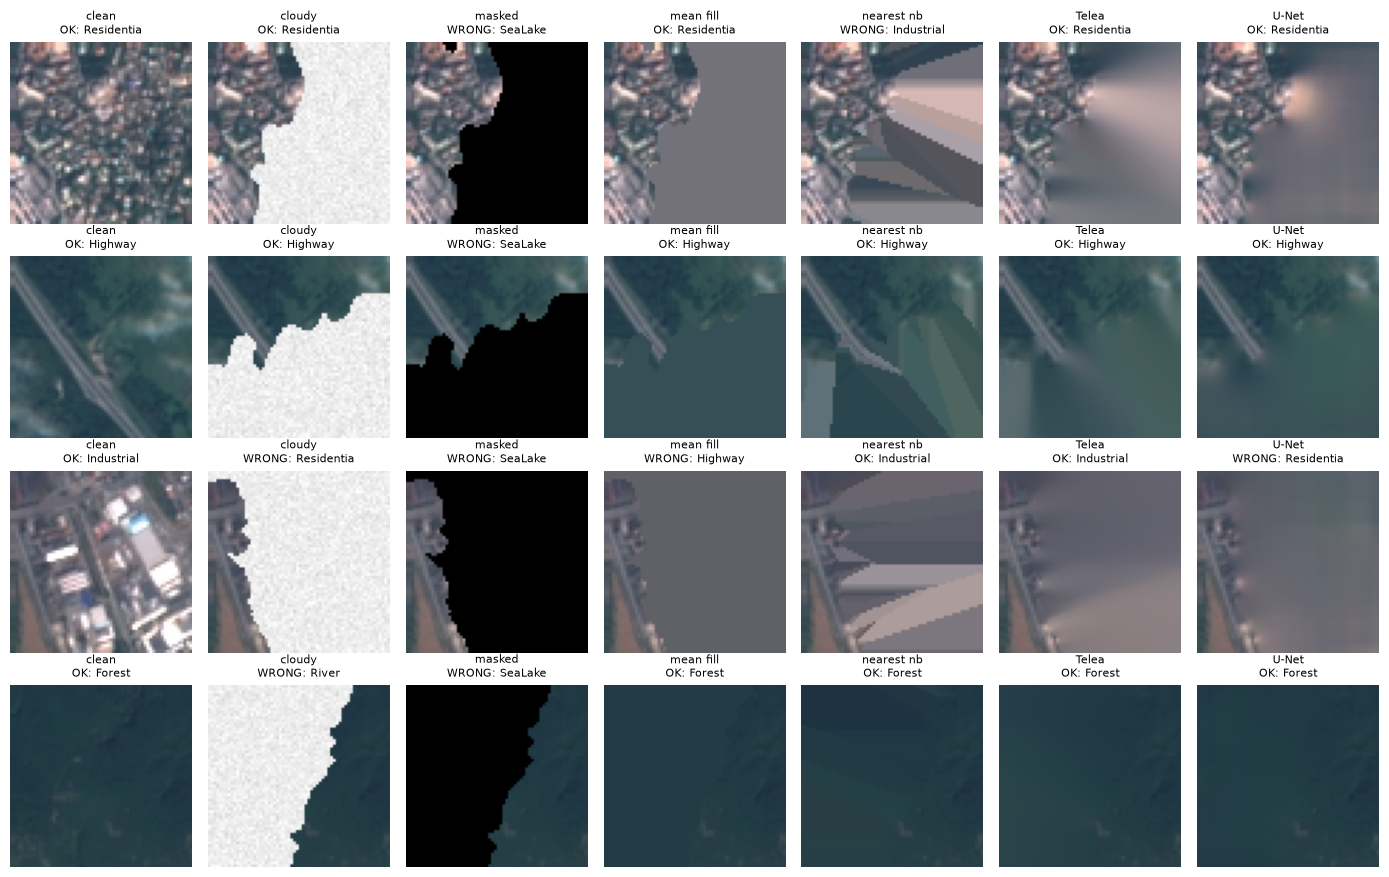

In [12]:
pick = []
for c in ["Residential", "Highway", "Industrial", "Forest"]:
    ii = np.where(test_df["class_name"].values == c)[0]
    if len(ii): pick.append(int(ii[0]))
names = ["clean", "cloudy", "masked", "mean fill", "nearest nb", "Telea", "U-Net"]
fig, axes = plt.subplots(len(pick), 7, figsize=(14, 2.2 * len(pick)))
axes = np.atleast_2d(axes)
for r, idx in enumerate(pick):
    rng = np.random.default_rng(42 + idx * 10 + 2)
    m = sim.generate_cloud_mask(BINS["60-80%"], rng=rng); cl = apply_thick(X[idx], m, rng)
    un = net_fill(unet, cl[None], m[None])[0]
    imgs = [X[idx], cl, masked_input(cl, m, 0), mean_fill(cl, m), nearest_neighbor_fill(cl, m), telea_inpaint(cl, m), un]
    for c_, (nm, im) in enumerate(zip(names, imgs)):
        p = int(predict(clf["fill_aware"], im[None])[0])
        ax = axes[r, c_]; ax.imshow(im); ax.axis("off")
        ax.set_title(f"{nm}\n{'OK' if p == y[idx] else 'WRONG'}: {CLASSES[p][:10]}", fontsize=8)
plt.tight_layout(); plt.show()

## 11. Reproduced headline numbers vs report

In [13]:
display(pd.DataFrame(SUMMARY, columns=["claim", "report", "this notebook"]))

,claim,report,this notebook
0,"Fill-aware Telea minus masked, 10-30%",+5.2,+5.2
1,"Fill-aware Telea minus masked, 30-60%",+8.3,+8.3
2,"Fill-aware Telea minus masked, 60-80%",+13.2,+13.2
3,Telea vs U-Net at 60-80% (fill-aware),0.830 vs 0.826,0.830 vs 0.826
4,Pooled rho vs harmful flips: Whole-tile SSIM,-0.21,-0.21
5,Pooled rho vs harmful flips: Full-tile LPIPS,+0.22,+0.22
6,Pooled rho vs harmful flips: In-mask PSNR,-0.12,-0.12
7,Pooled rho vs harmful flips: In-mask SSIM,-0.09,-0.09
8,"Harmful flips, Telea 60-80% / mean fill 60-80%",13.9 / 17.9,13.9 / 17.9
9,Opacity crossover alpha,~0.65 (sampled points; interpolated value shown),0.67


**Notes.** Clouds are synthetic and white on 64×64 RGB EuroSAT tiles; RICE results use classifier agreement as a proxy (no land-cover labels). Tables I, VI and VII use stored outputs of the multi-seed training runs; sections 4, 6 and the live transfer check re-run inference with the saved weights.